# Thesis results: controller comparison without occupants

These are the saved final thesis results for 25 Vermont homes, from `ce1_occ_p2s2_all_occ`. January supplies commissioning data; February and March are deployment months. Run all cells to read the versioned CSVs and figures. This notebook does not train or simulate controllers. See [reproduction and provenance](../docs/reproduction.md) and the [artifact manifest](artifact_manifest.json).

MPC uses a fitted 2R2C model with Kalman correction. GNU-RL uses a differentiable 1R1C MPC policy with online adaptation. SAC receives January training and February continuation before March. Safe-PI/RBC is the controlled baseline; the CityLearn dataset baseline is a separate reference.

Table VII averages normalized **building-level** scores after normalizing each building against its corresponding baseline. Lower scores are better; 1 means baseline for normalized load metrics. Comfort is a percentage of evaluated steps outside the band. KH measures reference-tracking Kelvin-hours and is not interchangeable with discomfort percentage. The Grid column averages ramping, 1-LF, daily peak, and maximum peak scores.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis/artifact_manifest.json').is_file())
DATA = ROOT / 'analysis/data'
FIGURES = ROOT / 'analysis/figures'
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)


## Table VII — February

In [2]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_no_occupant_mean_building_kpis_february.csv'))

,controller,Elec. score,Daily peak,Max peak,Ramping,1-LF,Grid,Cold [%],Hot [%],Comfort [%],KH
0,Baseline,1.00,1.00,1.00,1.00,1.00,1.00,0.16,0.08,0.24,2.21
1,Safe-PI/RBC,0.82,1.22,1.10,2.50,1.31,1.53,15.31,26.40,41.71,1874.53
2,MPC,1.00,1.01,1.01,1.05,1.00,1.02,0.80,0.30,1.10,385.01
3,GNU-RL adaptive,1.00,1.02,1.00,1.07,1.01,1.03,2.45,1.49,3.94,478.61
4,SAC,0.89,0.96,0.97,1.05,1.07,1.01,26.69,0.40,27.09,978.96


## Table VII — March

In [3]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_no_occupant_mean_building_kpis_march.csv'))

,controller,Elec. score,Daily peak,Max peak,Ramping,1-LF,Grid,Cold [%],Hot [%],Comfort [%],KH
0,Baseline,1.00,1.00,1.00,1.00,1.00,1.00,0.63,0.44,1.08,2.18
1,Safe-PI/RBC,0.80,1.15,1.04,2.42,1.27,1.47,13.25,20.93,34.18,1651.86
2,MPC,1.01,1.01,1.01,1.01,0.99,1.00,0.63,0.54,1.17,472.62
3,GNU-RL adaptive,1.01,1.02,1.02,1.04,0.99,1.02,2.29,1.45,3.75,507.94
4,SAC,0.97,1.00,1.01,1.04,1.01,1.02,4.88,0.82,5.70,561.73


MPC has 1.10% and 1.17% total discomfort in February and March; GNU-RL has 3.94% and 3.75%. SAC improves from 27.09% to 5.70% after continuation. Safe-PI/RBC has 41.71% and 34.18%. Reduced electricity use must be interpreted alongside comfort: underheating can produce an apparently favorable energy score.

## Representative buildings: February and March

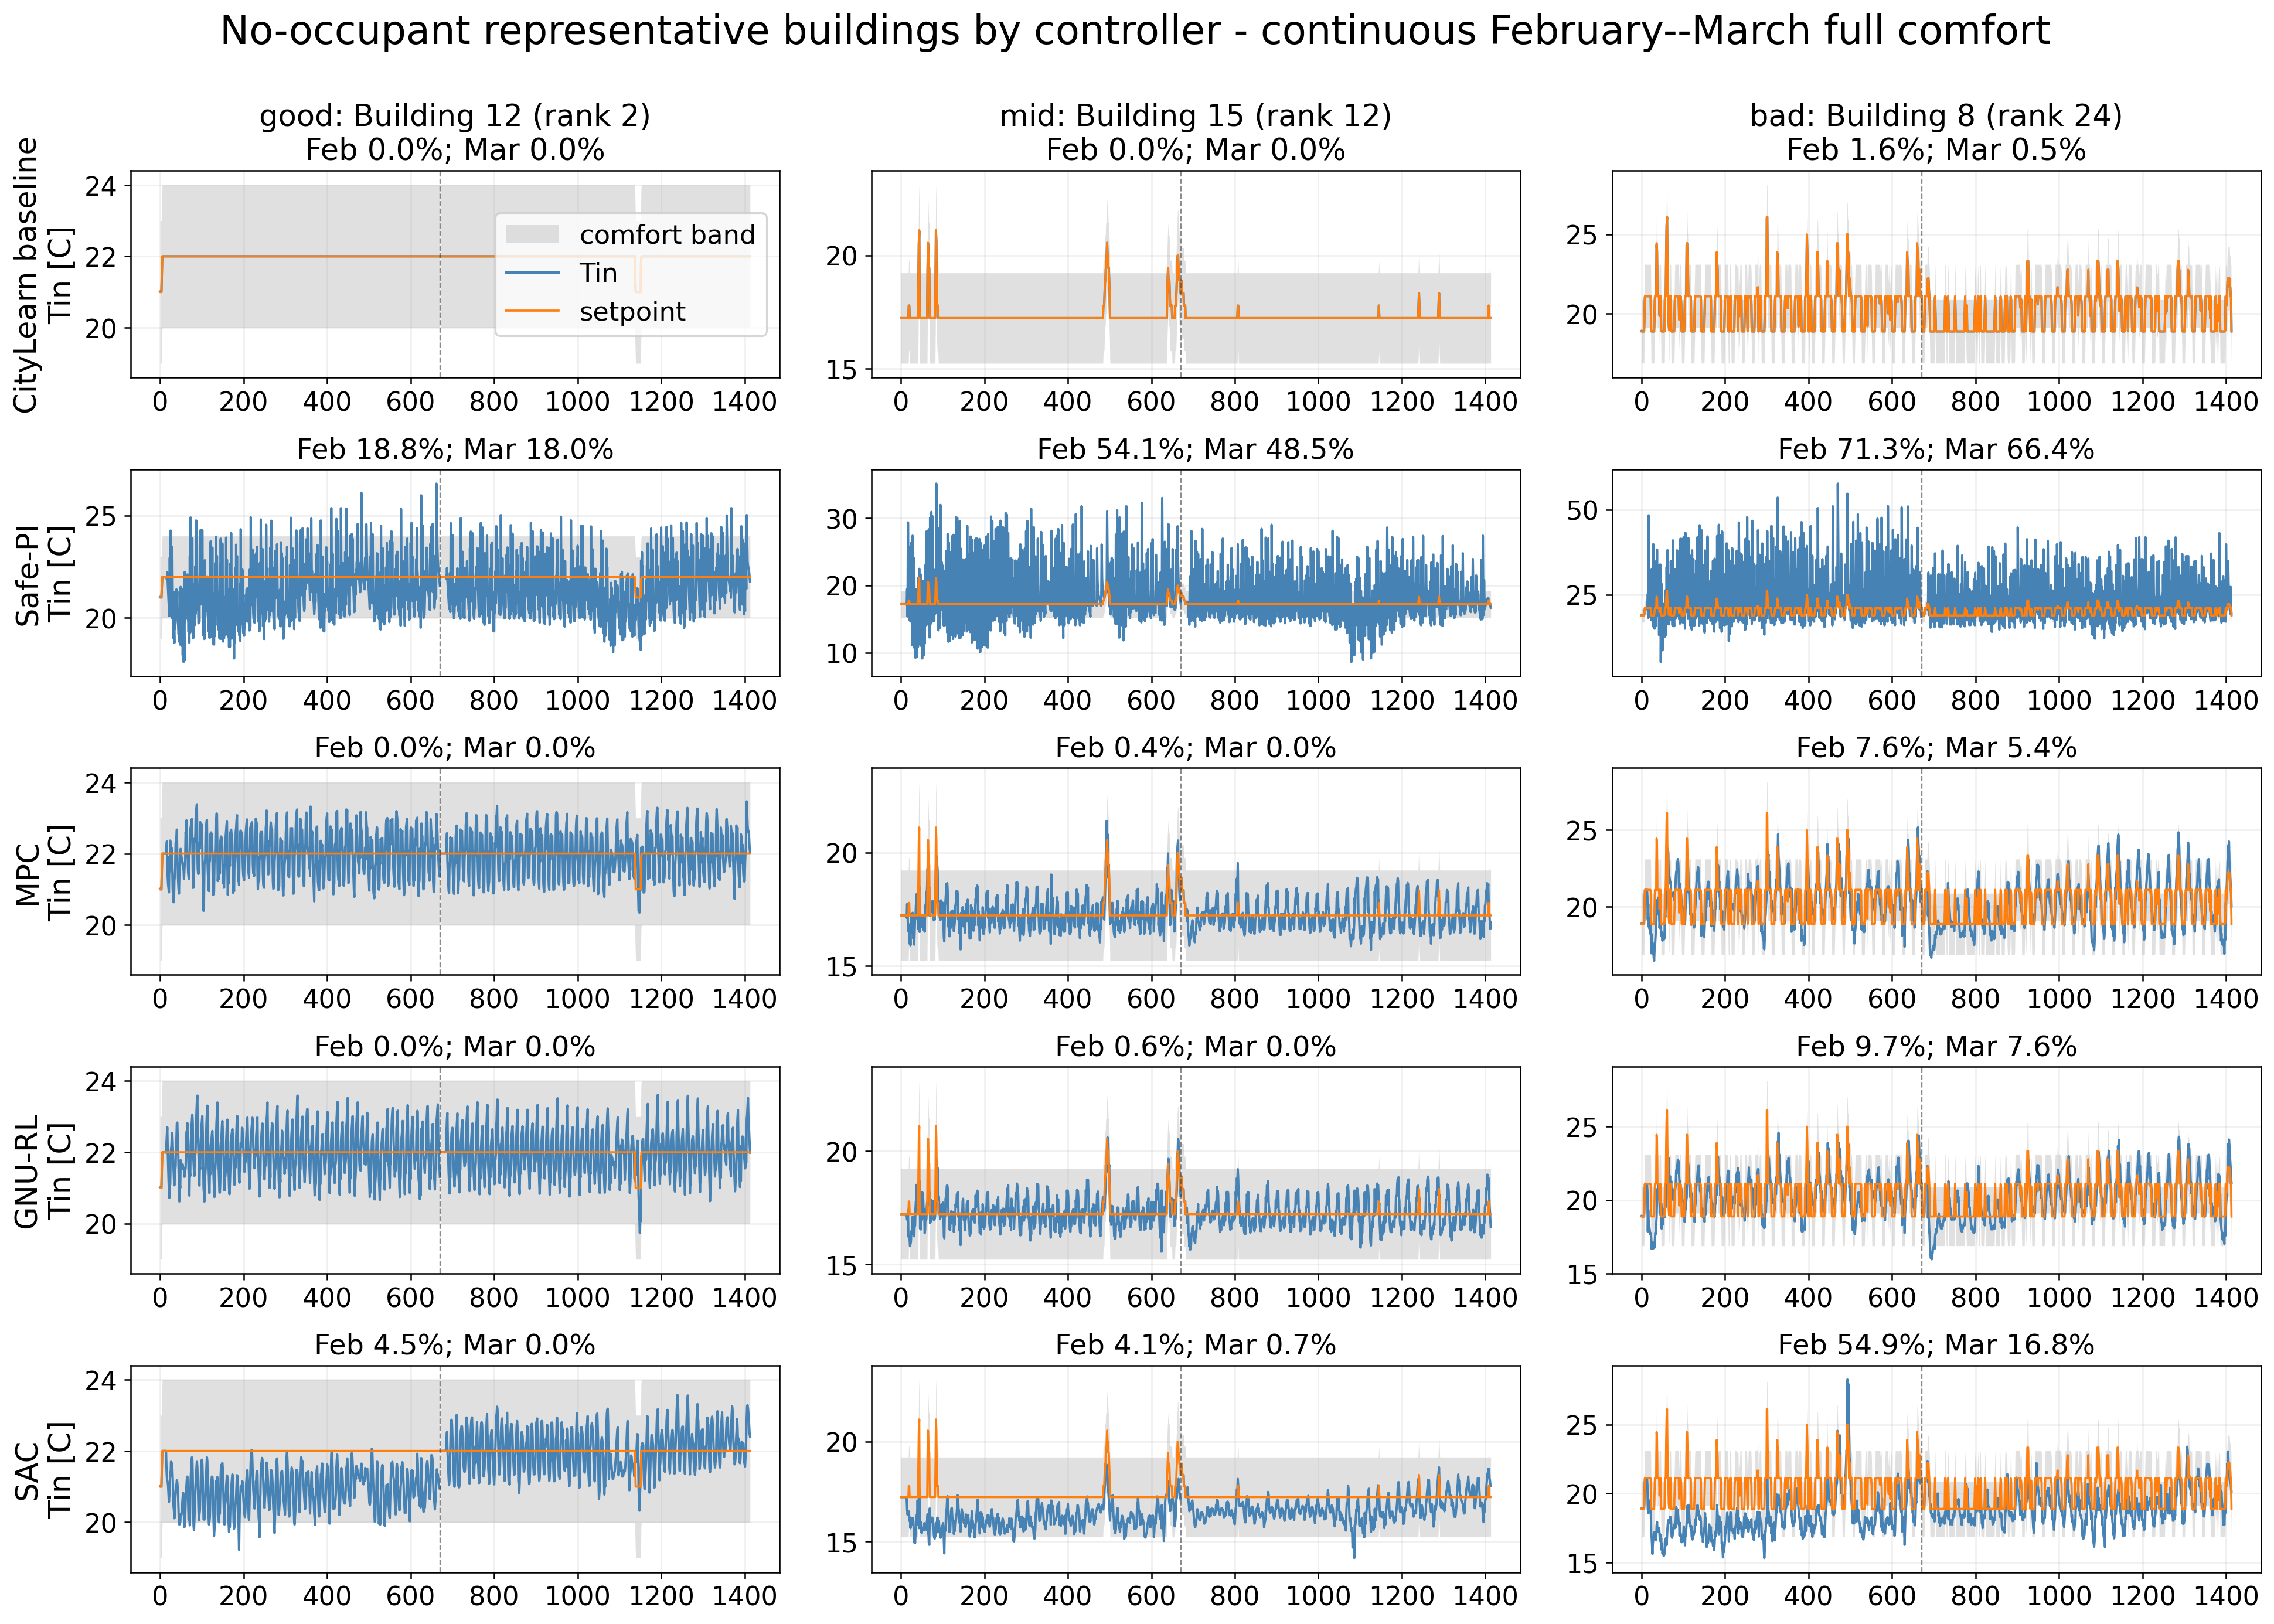

In [4]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/thesis_no_occupant_selected_controllers_month.png'))) 

## Representative buildings: daily profiles

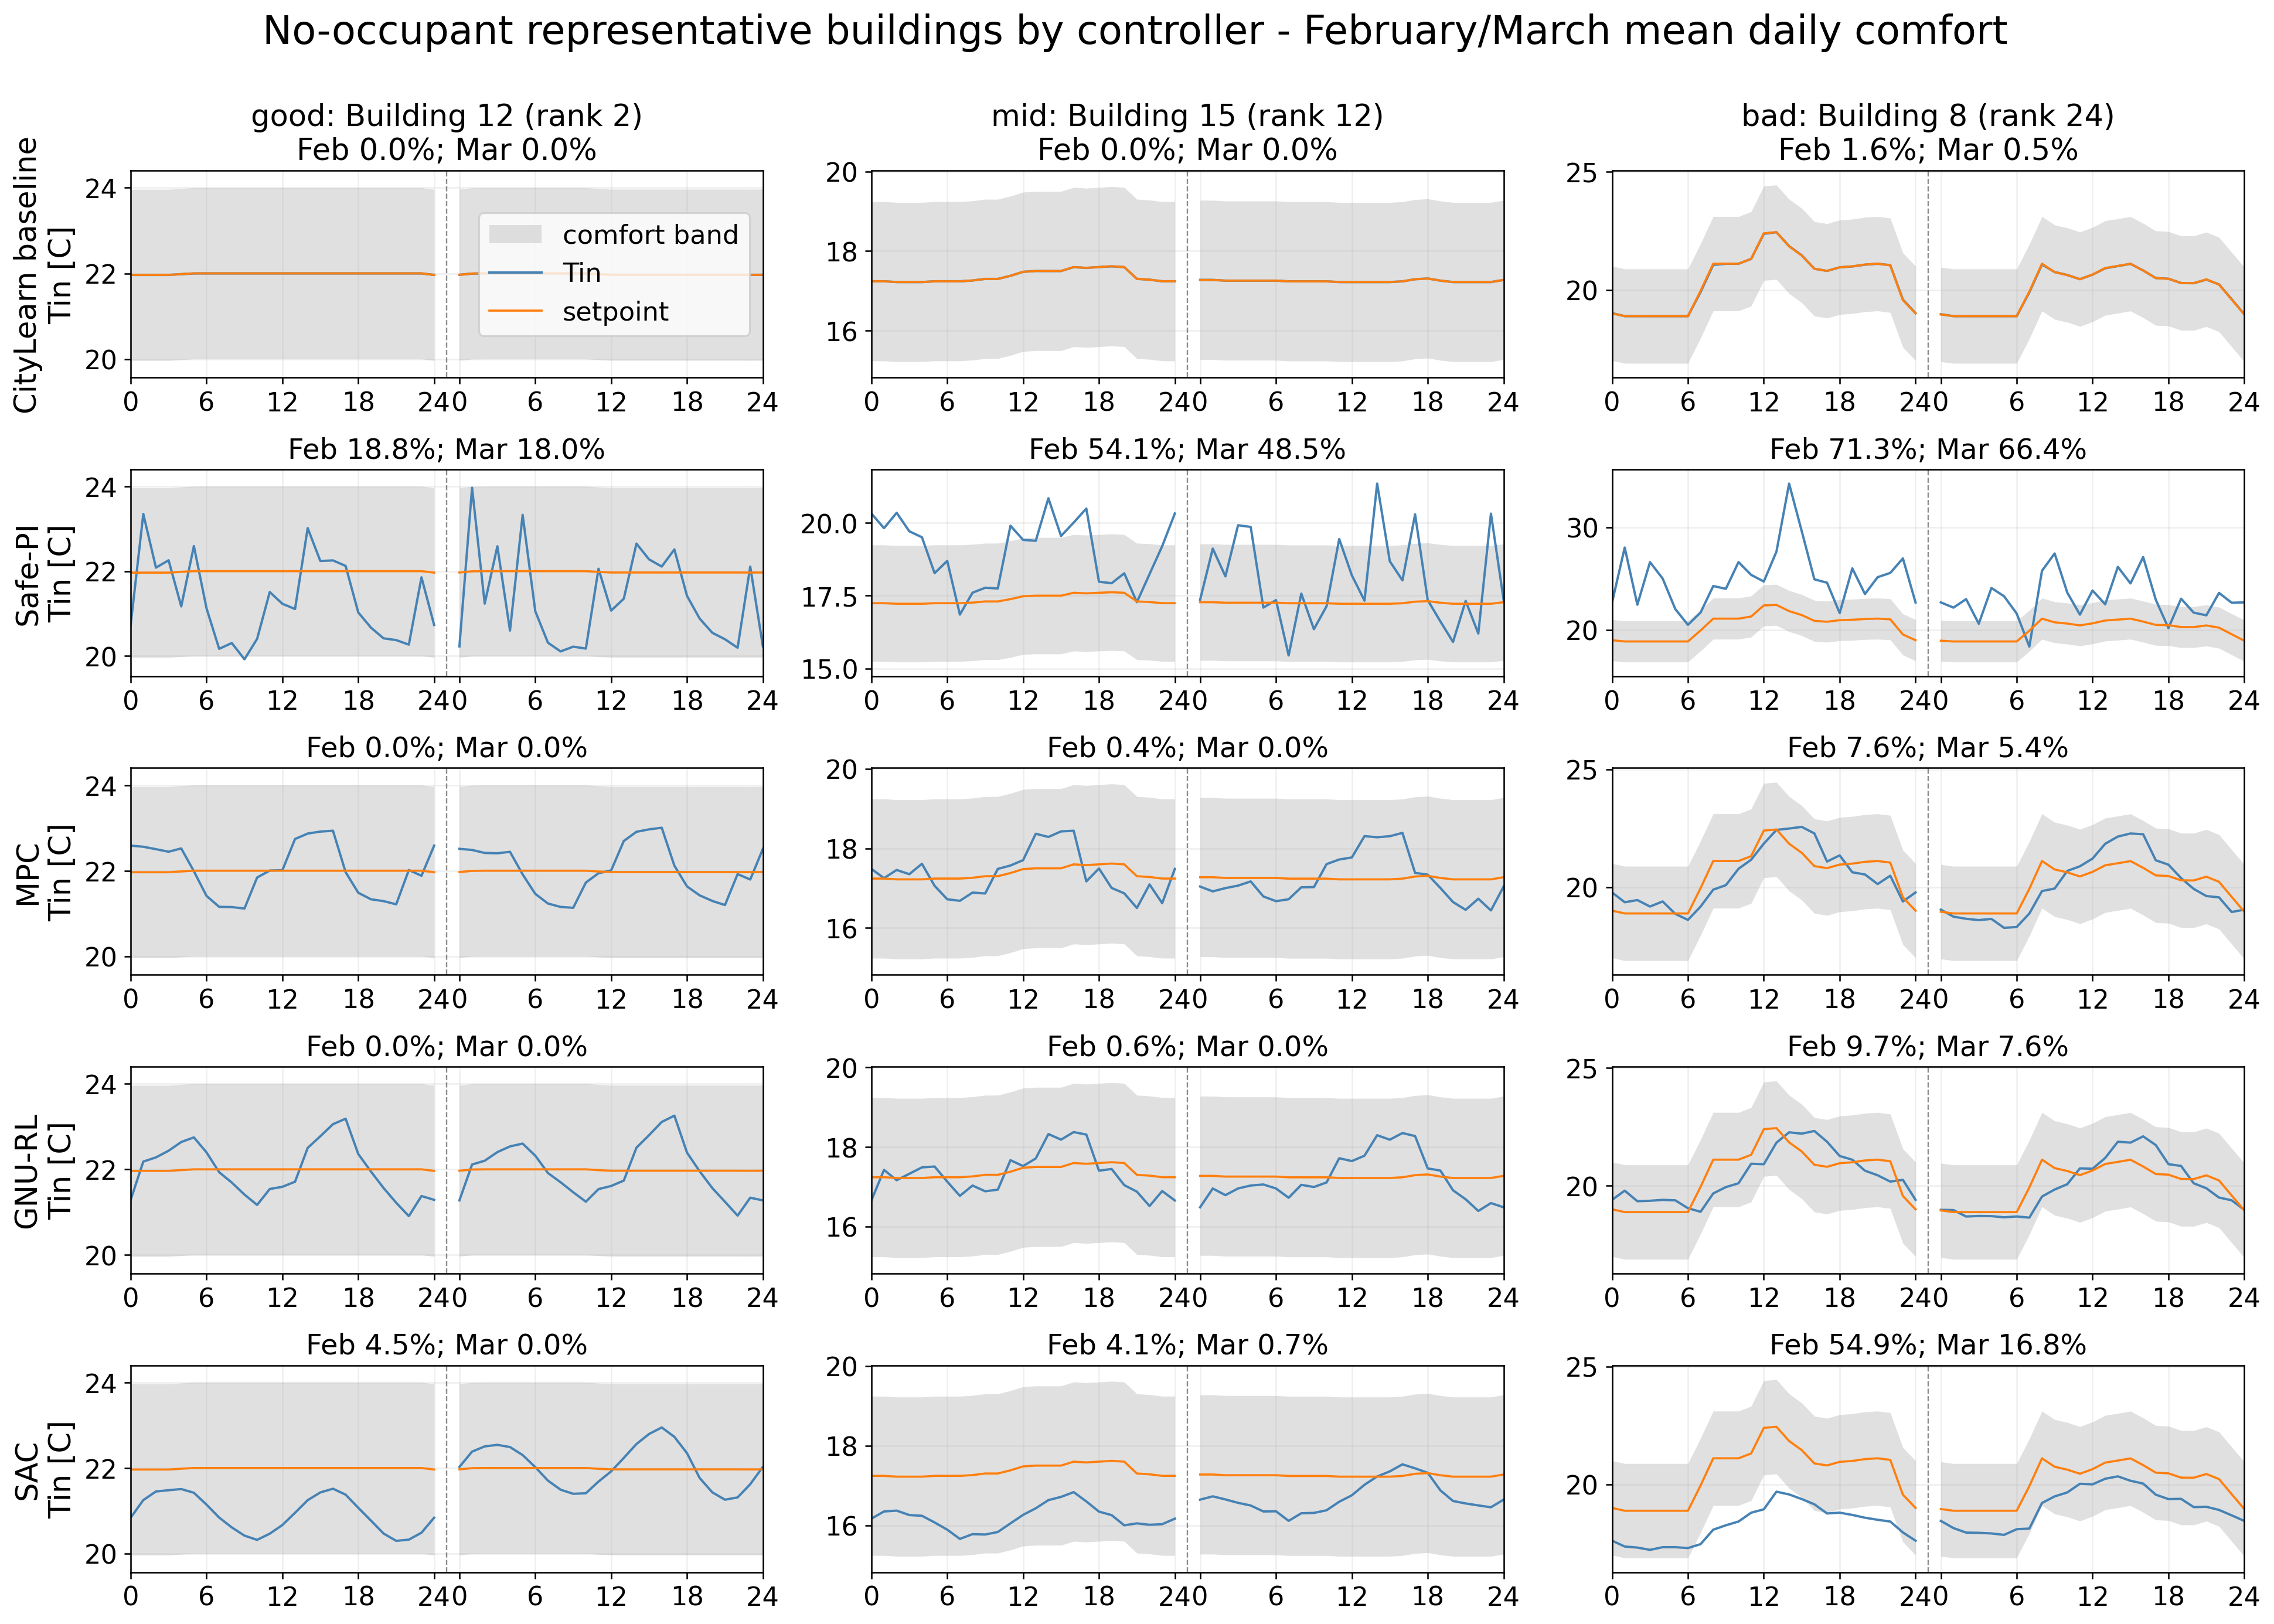

In [5]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/thesis_no_occupant_selected_controllers_mean_daily.png'))) 

The thesis fixes three illustrative buildings across comparisons: Building 12 (good), Building 15 (middle), and Building 8 (difficult). These are selected examples; the portfolio tables above cover all 25 homes.

## Table VIII — selected buildings, February

In [6]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_no_occupant_selected_building_kpis_february.csv'))

,month,building_id,building,controller,electricity_consumption_total,daily_peak_average,all_time_peak_average,ramping_average,daily_one_minus_load_factor_average,grid_efficiency_cost,discomfort_cold_proportion,discomfort_hot_proportion,comfort_cost,kelvin_hours
0,February,building_08,Building 8,Safe-PI/RBC,0.76,1.46,1.26,3.08,1.54,1.83,21.93,49.40,71.33,4545.66
1,February,building_08,Building 8,MPC,0.99,1.01,1.03,0.93,1.00,0.99,4.66,2.94,7.60,559.31
2,February,building_08,Building 8,GNU-RL adaptive model,0.99,1.01,1.03,0.96,1.01,1.00,6.39,3.28,9.67,683.80
3,February,building_08,Building 8,SAC,0.85,0.93,0.98,0.95,1.09,0.99,53.71,1.21,54.92,1533.10
4,February,building_12,Building 12,Safe-PI/RBC,0.84,1.02,1.04,1.68,1.10,1.21,15.66,3.10,18.76,924.15
5,February,building_12,Building 12,MPC,0.98,1.02,1.02,1.11,1.02,1.05,0.00,0.00,0.00,216.09
6,February,building_12,Building 12,GNU-RL adaptive model,0.98,1.03,1.03,1.11,1.03,1.05,0.00,0.00,0.00,383.28
7,February,building_12,Building 12,SAC,0.89,0.99,1.02,1.09,1.06,1.04,4.50,0.00,4.50,712.15
8,February,building_15,Building 15,Safe-PI/RBC,0.89,1.26,1.16,2.59,1.26,1.57,17.23,36.89,54.12,2392.46
9,February,building_15,Building 15,MPC,1.00,1.02,1.02,1.07,1.01,1.03,0.37,0.00,0.37,348.52


## Building-level distributions — February

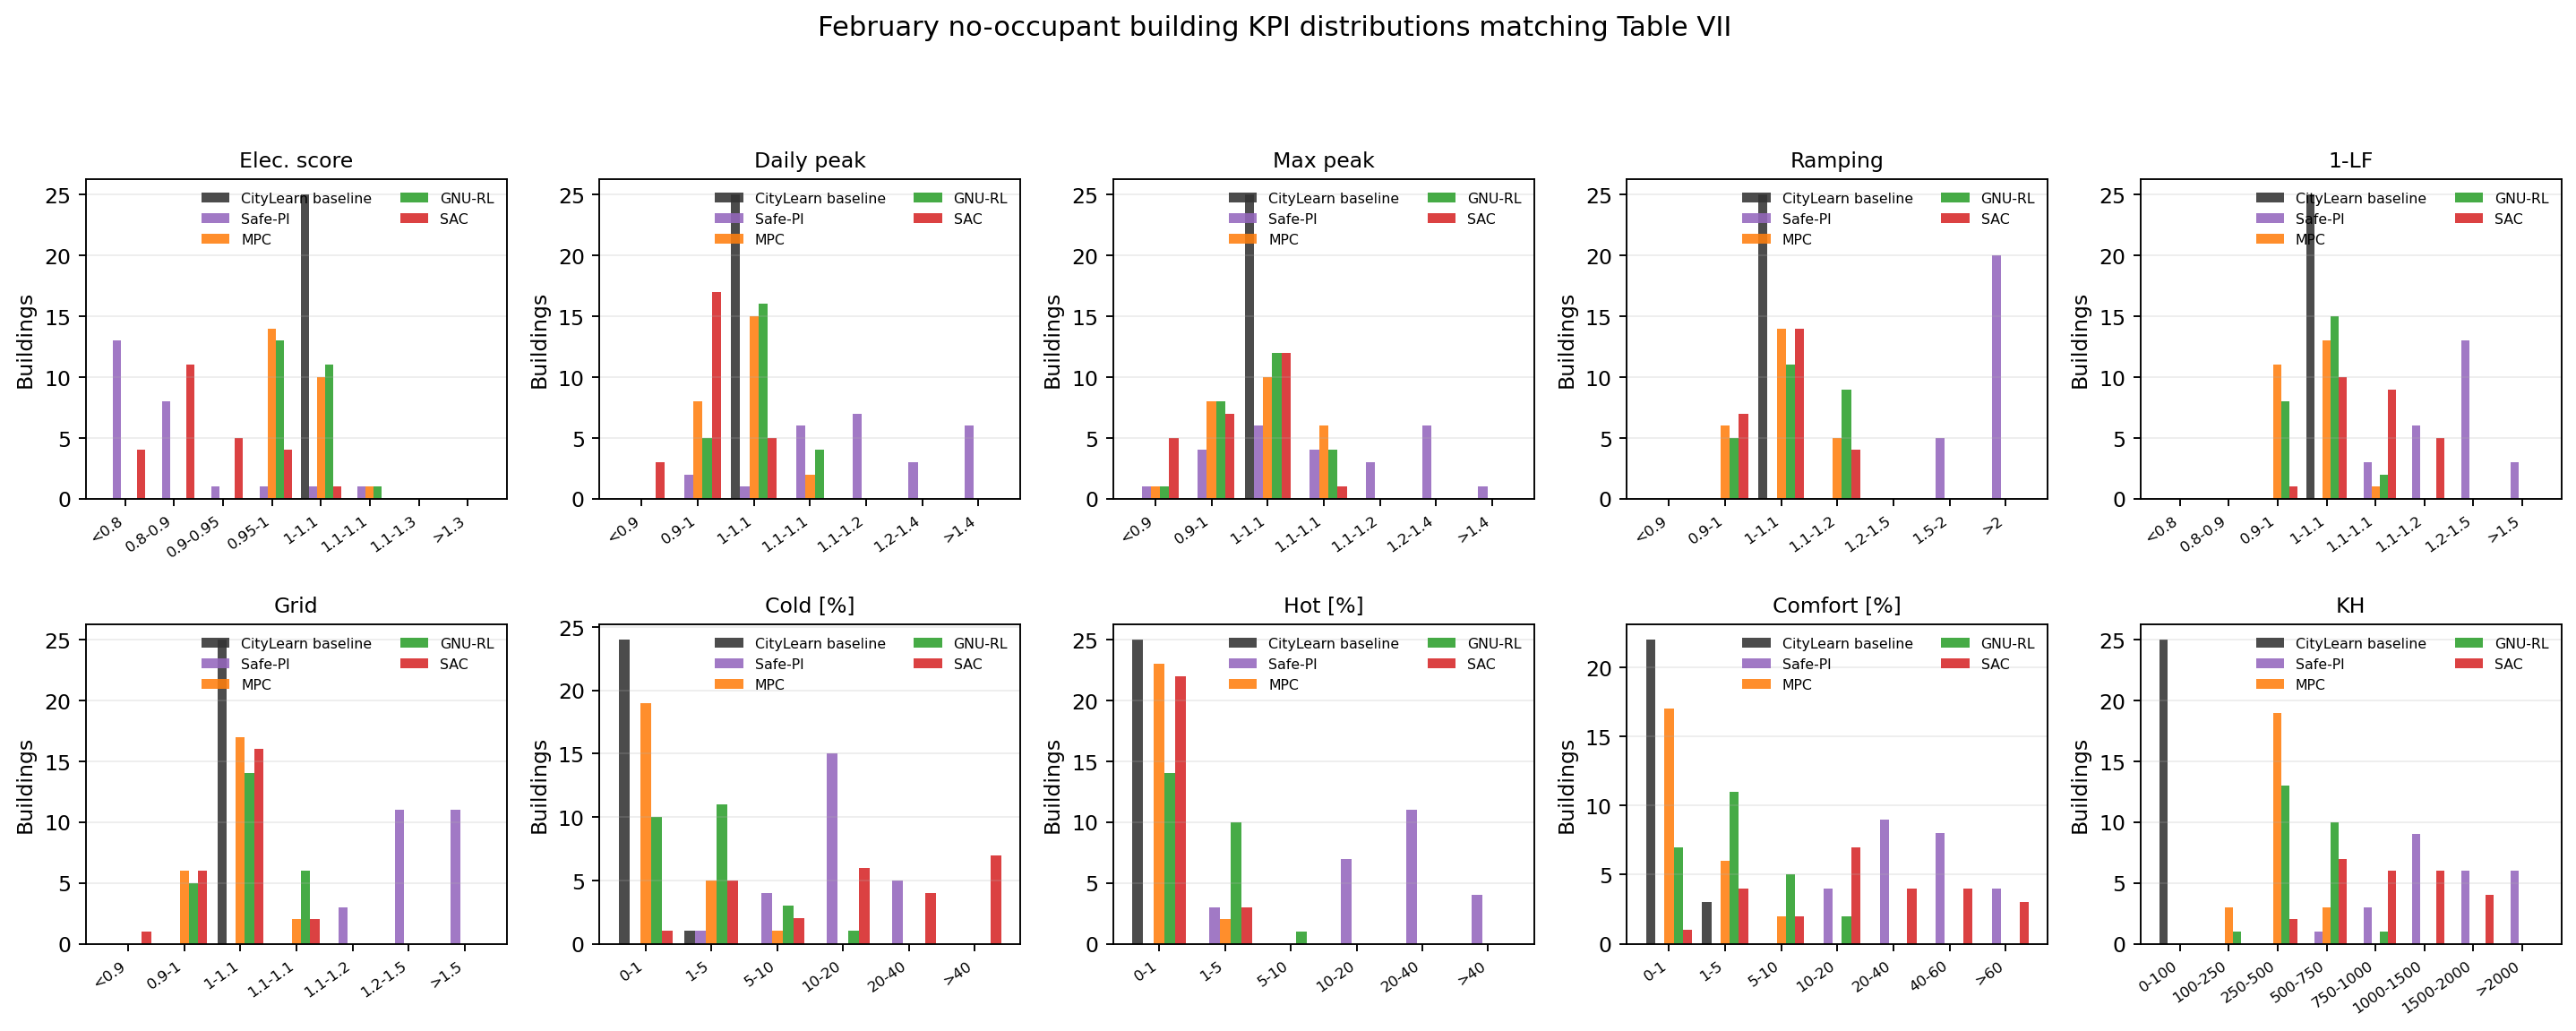

In [7]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/february_no_occupant_table_vii_histograms.png'))) 

## Table VIII — selected buildings, March

In [8]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_no_occupant_selected_building_kpis_march.csv'))

,month,building_id,building,controller,electricity_consumption_total,daily_peak_average,all_time_peak_average,ramping_average,daily_one_minus_load_factor_average,grid_efficiency_cost,discomfort_cold_proportion,discomfort_hot_proportion,comfort_cost,kelvin_hours
0,March,building_08,Building 8,Safe-PI/RBC,0.71,1.32,1.10,3.09,1.48,1.75,21.62,44.79,66.41,3608.02
1,March,building_08,Building 8,MPC,1.00,0.99,0.99,0.91,0.97,0.96,2.64,2.80,5.44,634.14
2,March,building_08,Building 8,GNU-RL adaptive model,1.00,1.00,1.02,0.95,0.99,0.99,4.67,2.95,7.62,614.43
3,March,building_08,Building 8,SAC,0.92,0.97,0.97,0.98,1.05,0.99,16.49,0.31,16.80,874.89
4,March,building_12,Building 12,Safe-PI/RBC,0.84,0.99,1.00,1.49,1.07,1.14,14.65,3.38,18.03,922.66
5,March,building_12,Building 12,MPC,0.96,1.02,1.01,1.08,1.03,1.03,0.00,0.00,0.00,260.47
6,March,building_12,Building 12,GNU-RL adaptive model,0.96,1.04,1.02,1.08,1.04,1.04,0.00,0.00,0.00,409.03
7,March,building_12,Building 12,SAC,0.97,1.04,1.01,1.07,1.03,1.04,0.00,0.00,0.00,381.05
8,March,building_15,Building 15,Safe-PI/RBC,0.86,1.08,0.92,2.30,1.14,1.36,18.20,30.27,48.47,1961.50
9,March,building_15,Building 15,MPC,0.99,1.02,1.01,1.04,1.01,1.02,0.00,0.00,0.00,518.08


## Building-level distributions — March

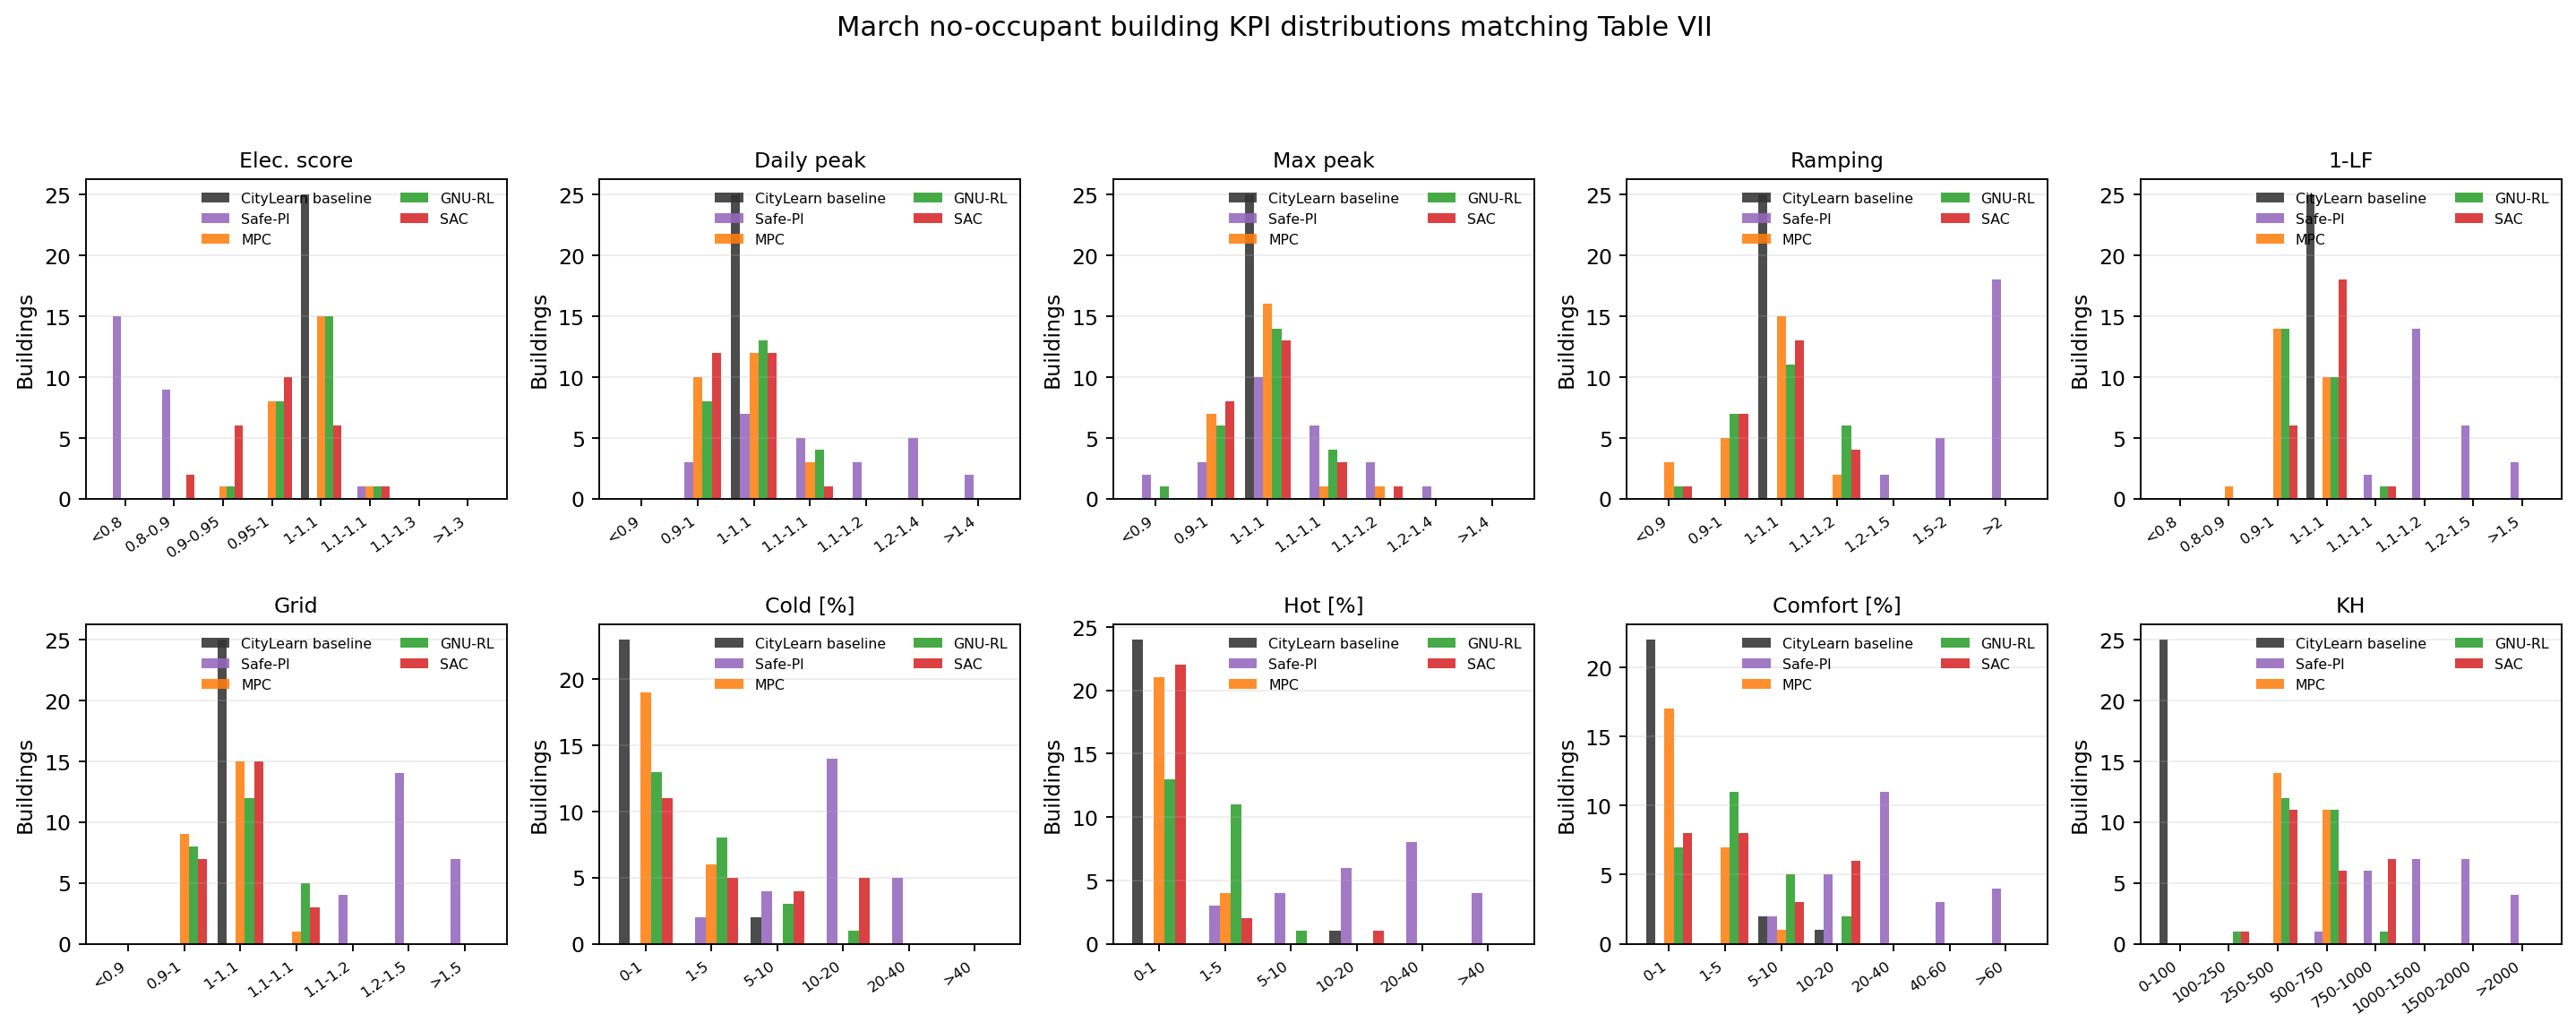

In [9]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/march_no_occupant_table_vii_histograms.png'))) 

## GNU-RL online adaptation diagnostics

In [10]:
display(pd.read_csv(DATA / 'ce1_occ_p2s2_all_occ_gnurl_adaptive_ppo_delta_summary.csv'))

,month,mode,cases,better,worse,mean_improve_pp,median_improve_pp,p25,p75
0,February,bspline_tdyn,100,40,46,-0.03,-0.00,-0.32,0.19
1,February,no_occupant,25,2,4,-0.02,-0.00,0.00,0.00
2,February,without_tdyn,100,49,47,-0.05,-0.00,-1.13,0.65
3,March,bspline_tdyn,100,37,42,-0.08,-0.00,-0.36,0.17
4,March,no_occupant,25,4,5,0.02,-0.00,0.00,0.00
5,March,without_tdyn,100,53,35,0.24,0.15,-0.28,0.80
